## Model B — unseen Track

Train on all athletes from the other two sports; test on **all Track athletes**. Use the binary target and the same models, searches and cutoff selection as binary A, **without sport as a predictor**.

**0 = Not high risk**, **1 = High Risk/Injured**.

### 4.1 Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, fbeta_score, make_scorer,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import (StratifiedGroupKFold,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
SPORTS = ['Football', 'Basketball', 'Track']
TARGET = 'injury_occurred'
LABELS = ['Not high risk', 'High Risk/Injured']
SURFACES = {0: 'Grass', 1: 'Turf', 2: 'Indoor', 3: 'Track', 4: 'Other'}
TEST_SPORT = 'Track'
TRAIN_SPORTS = [sport for sport in SPORTS if sport != TEST_SPORT]

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)

### 4.2 Load and define the binary target

In [2]:
project_dir = Path.cwd()
if not (project_dir / 'multimodal_sports_injury_dataset.csv').exists():
    project_dir = project_dir / 'final_proj'
df = pd.read_csv(project_dir / 'multimodal_sports_injury_dataset.csv')
for col in ['sport_type', 'gender']:
    df[col] = df[col].astype('string').str.strip()
df['sport_type'] = df['sport_type'].replace({'Soccer': 'Football'})
df = df.loc[df['sport_type'].isin(SPORTS)].copy()
assert df[TARGET].isin([0, 1, 2]).all(), 'Unknown or missing source target.'
df['playing_surface'] = df['playing_surface'].map(SURFACES).astype('category')
df['gender'] = df['gender'].astype('category')

# Keep original labels; define binary target separately.
y = df[TARGET].eq(2).astype(int).rename('high_risk')
X = df.drop(columns=['athlete_id', 'session_id', 'sport_type', TARGET])
print(f'{len(df):,} sessions from {df.athlete_id.nunique()} athletes')

13,043 sessions from 132 athletes


### 4.3 Hold out the entire sport

No permanent split within source sports. Grouped CV uses source athletes only; the final pipelines refit on every source athlete.

In [3]:
train_mask = df['sport_type'].isin(TRAIN_SPORTS)
test_mask = df['sport_type'].eq(TEST_SPORT)
train_ids = df.loc[train_mask, 'athlete_id'].unique()
test_ids = df.loc[test_mask, 'athlete_id'].unique()
assert set(train_ids).isdisjoint(test_ids), 'An athlete appears on both sides.'

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]
groups_train = df.loc[train_mask, 'athlete_id']
display(df.assign(partition=np.where(train_mask, 'Train', 'Test')).groupby(
    ['sport_type', 'partition']
).agg(athletes=('athlete_id', 'nunique'), sessions=('athlete_id', 'size')))
print('Training sports:', ', '.join(TRAIN_SPORTS))
print('Held-out sport:', TEST_SPORT)
print(f'Positive rate in training: {y_train.mean():.1%}')

,,athletes,sessions
sport_type,partition,,
Basketball,Train,41,4059
Football,Train,49,4837
Track,Test,42,4147


Training sports: Football, Basketball
Held-out sport: Track
Positive rate in training: 14.9%


### 4.4 Pipelines and grouped folds

Fit imputers and encoders inside each source-training fold. CV measures generalization to source athletes; the held-out sport tests cross-sport transfer.

In [4]:
categorical_features = ['playing_surface', 'gender']
numeric_features = [c for c in X.columns if c not in categorical_features]

def make_model(estimator):
    preprocess = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numeric_features),
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', drop=None)),
        ]), categorical_features),
    ])
    return Pipeline([('preprocess', preprocess), ('model', estimator)])

# Balance labels while keeping each athlete together.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
# Reuse identical source-only folds across all models.
folds = list(cv.split(X_train, y_train, groups=groups_train))
fold_rows = []
for fold, (fit_idx, valid_idx) in enumerate(folds, start=1):
    fit_groups = groups_train.iloc[fit_idx]
    valid_groups = groups_train.iloc[valid_idx]
    assert set(fit_groups).isdisjoint(valid_groups), 'An athlete crosses a CV fold.'
    # Count validation athletes separately within each source sport.
    valid_athletes = df.loc[X_train.iloc[valid_idx].index, ['athlete_id', 'sport_type']].drop_duplicates()
    counts = valid_athletes['sport_type'].value_counts().reindex(TRAIN_SPORTS, fill_value=0)
    fold_rows.append({'Fold': fold, 'Train athletes': fit_groups.nunique(),
                      'Validation athletes': valid_groups.nunique(),
                      'Validation positive rate': y_train.iloc[valid_idx].mean(),
                      **counts.to_dict()})
display(pd.DataFrame(fold_rows).set_index('Fold').round(3))

,Train athletes,Validation athletes,Validation positive rate,Football,Basketball
Fold,,,,,
1,72,18,0.146,9,9
2,72,18,0.151,13,5
3,72,18,0.147,9,9
4,72,18,0.148,10,8
5,72,18,0.152,8,10


### 4.5 Scoring and search spaces

Match A: tune by F2, also record AP. Try 18 tree settings and 12 sampled forest settings with 200 trees. Select cutoffs afterward using training predictions only.

In [5]:
# Track both metrics during each search.
scoring = {'f2': make_scorer(fbeta_score, beta=2, zero_division=0),  # Wrap F2 for CV scoring.
           'ap': 'average_precision'}
tree_grid = {
    'model__max_depth': [3, 6, None],
    'model__min_samples_leaf': [5, 20, 50],
    'model__class_weight': [None, 'balanced'],
}
forest_grid = {
    'model__max_depth': [6, 12, None],
    'model__min_samples_leaf': [2, 10, 30],
    'model__max_features': ['sqrt', 0.5],
    'model__class_weight': [None, 'balanced'],
}
searches = {}

### 4.6 Decision tree

In [6]:
tree_search = GridSearchCV(
    make_model(DecisionTreeClassifier(random_state=SEED)),
    tree_grid, scoring=scoring, refit='f2', cv=folds,  # Select the model using F2.
    n_jobs=2, pre_dispatch=2, error_score='raise',
)
tree_search.fit(X_train, y_train)
searches['Decision tree'] = tree_search
print('Best tree settings:', tree_search.best_params_)
print(f'CV F2 at default cutoff: {tree_search.best_score_:.3f}')

Best tree settings: {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 5}
CV F2 at default cutoff: 0.663


### 4.7 Random forest

In [7]:
forest_search = RandomizedSearchCV(
    make_model(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)),
    forest_grid, n_iter=12, random_state=SEED,
    scoring=scoring, refit='f2', cv=folds,  # Select the model using F2.
    n_jobs=2, pre_dispatch=2, error_score='raise',
)
forest_search.fit(X_train, y_train)
searches['Random forest'] = forest_search
print('Best forest settings:', forest_search.best_params_)
print(f'CV F2 at default cutoff: {forest_search.best_score_:.3f}')

Best forest settings: {'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': 6, 'model__class_weight': 'balanced'}
CV F2 at default cutoff: 0.680


### 4.8 Select thresholds on source athletes

Match A's cutoff grid and F2 rule. Hyperparameters and cutoffs reuse folds, making selection scores optimistic. Freeze both before testing; these scores are not calibrated clinical probabilities.

In [8]:
models, thresholds = {}, {}
threshold_tables = {}
selection_rows = []
# Search cutoffs using training predictions only.
cutoffs = np.round(np.linspace(0.05, 0.95, 19), 2)
for key, search in searches.items():
    # Predict each athlete without training on them.
    oof_prob = cross_val_predict(
        search.best_estimator_, X_train, y_train, cv=folds,
        method='predict_proba', n_jobs=2, pre_dispatch=2,  # Return class probabilities, not labels.
    )[:, 1]  # Select probabilities for the high-risk class.
    candidates = []
    for cutoff in cutoffs:
        # Convert scores into alerts using this cutoff.
        predicted = (oof_prob > cutoff).astype(int)
        candidates.append({'Threshold': cutoff,
                           'F2': fbeta_score(y_train, predicted, beta=2, zero_division=0),
                           'Recall': recall_score(y_train, predicted, zero_division=0),
                           'Precision': precision_score(y_train, predicted, zero_division=0)})
    # Break equal-score ties with higher cutoffs.
    table = pd.DataFrame(candidates).sort_values(['F2', 'Threshold'], ascending=False)
    chosen = table.iloc[0]
    models[key] = search.best_estimator_  # Already refitted on all training athletes.
    thresholds[key] = chosen['Threshold']
    threshold_tables[key] = table
    selection_rows.append({'Model': key,
                           'CV F2 at 0.5': search.best_score_,
                           'CV std': search.cv_results_['std_test_f2'][search.best_index_],
                           'OOF AP': average_precision_score(y_train, oof_prob),
                           'Threshold': chosen['Threshold'], 'OOF selected F2': chosen['F2']})
selection = pd.DataFrame(selection_rows).set_index('Model').sort_index()
display(selection.round(3))

,CV F2 at 0.5,CV std,OOF AP,Threshold,OOF selected F2
Model,,,,,
Decision tree,0.663,0.008,0.464,0.50,0.663
Random forest,0.680,0.015,0.540,0.45,0.690


### 4.9 Dummy references

Never alert and always alert show the two extreme policies.

In [9]:
for name, label in [('Never alert', 0), ('Always alert', 1)]:
    key = name
    # Constant ignores features and predicts one label.
    model = make_model(DummyClassifier(strategy='constant', constant=label))
    model.fit(X_train, y_train)
    models[key] = model
    thresholds[key] = 0.5

### 4.10 All held-out Track athletes

No target athletes were used for model fitting, imputation, encoding, hyperparameter selection or cutoff selection. Report session-level false alarms and misses alongside F2, recall, precision and AP.

In [10]:
def scores(actual, probability, threshold):
    # Apply the cutoff fixed before test evaluation.
    predicted = (probability > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {'F2': fbeta_score(actual, predicted, beta=2, zero_division=0),
            'Recall': recall_score(actual, predicted, zero_division=0),
            'Precision': precision_score(actual, predicted, zero_division=0),
            'F1': f1_score(actual, predicted, zero_division=0),
            # Average precision evaluates ranking across thresholds.
            'AP': average_precision_score(actual, probability),
            'Accuracy': accuracy_score(actual, predicted),
            'False alarms': int(fp), 'Missed positives': int(fn)}

test_predictions = df.loc[test_mask, ['athlete_id', 'sport_type', TARGET]].copy()
test_predictions['high_risk'] = y_test
probabilities = {}
test_rows = []
for key, model in models.items():
    # Get positive-class scores before applying the cutoff.
    probability = model.predict_proba(X_test)[:, 1]
    probabilities[key] = probability
    name = key
    test_predictions[name] = (probability > thresholds[key]).astype(int)
    test_rows.append({'Model': key, 'Threshold': thresholds[key],
                      **scores(y_test, probability, thresholds[key])})
test_results = pd.DataFrame(test_rows).set_index('Model').sort_index()
display(test_results.round(3))
print(f'Test positives: {y_test.sum()} / {len(y_test)} sessions; {len(test_ids)} athletes')

,Threshold,F2,Recall,Precision,F1,AP,Accuracy,False alarms,Missed positives
Model,,,,,,,,,
Always alert,0.50,0.478,1.000,0.155,0.268,0.155,0.155,3505,0
Decision tree,0.50,0.682,0.874,0.363,0.513,0.467,0.743,986,81
Never alert,0.50,0.000,0.000,0.000,0.000,0.155,0.845,0,642
Random forest,0.45,0.717,0.913,0.386,0.542,0.537,0.762,933,56


Test positives: 642 / 4147 sessions; 42 athletes


### 4.11 Errors and precision–recall curves

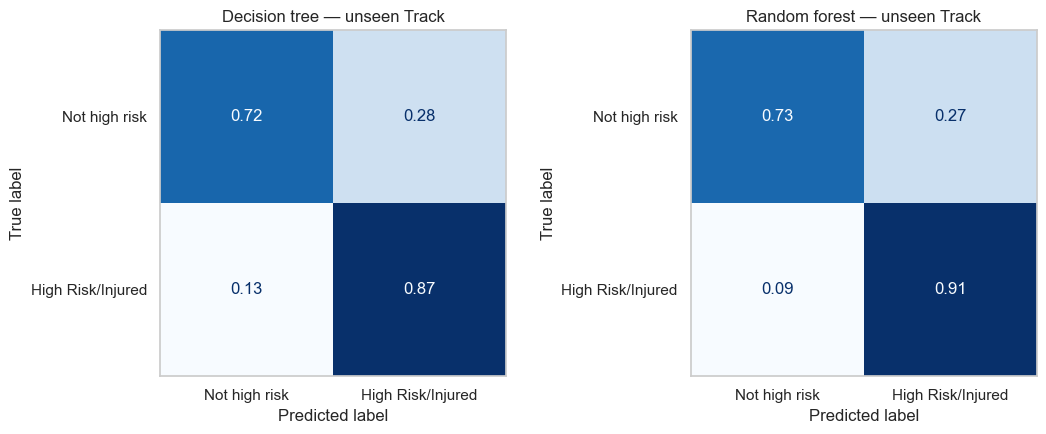

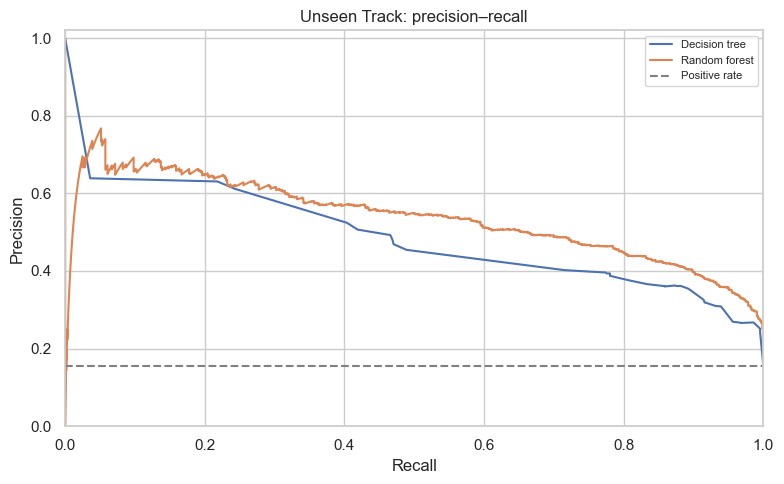

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, ax in zip(searches, axes):
    predicted = (probabilities[name] > thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=[0, 1], display_labels=LABELS,
        # Show proportions within each actual class.
        normalize='true', values_format='.2f', cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set_title(f'{name} — unseen {TEST_SPORT}')
    ax.grid(False)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for name in searches:
    # Trace precision and recall across score cutoffs.
    precision, recall, _ = precision_recall_curve(y_test, probabilities[name])
    ax.plot(recall, precision, label=name)
ax.axhline(y_test.mean(), color='grey', linestyle='--', label='Positive rate')
ax.set(xlabel='Recall', ylabel='Precision', title=f'Unseen {TEST_SPORT}: precision–recall',
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Interpretation

- Forest: **F2 0.717**, recall **0.913**, precision **0.386** at cutoff **0.45**; 56 misses and 933 false alarms.
- Tree: **F2 0.682**, recall **0.874**; 81 misses and 986 false alarms. The forest reduces both errors on these target athletes.
- Always alert catches every positive but produces 3,505 false alarms.

All 42 Track athletes were held out from fitting and tuning. These are supplied risk/status labels. A uses a smaller target subset; match target athletes before calculating a paired transfer gap. Source composition and training sizes differ too. Outputs stay inline.